# Laboratorium 2: analiza podobieństwa obrazów przy pomocy PCA i Incremental PCA

## Inteligentne przetwarzanie sygnałów

- Maksymalna liczba punktów: 10
- Skala ocen za punkty: 9–10 → 5.0; 8 → 4.5; 7 → 4.0; 6 → 3.5; 5 → 3.0; 0–4 → 2.0

Na tym laboratorium zapoznamy się z zastosowaniem PCA i Incremental PCA do generowania cech z obrazów. Aby ta metoda była skuteczna, musi być spełnionych kilka warunków:
- Obrazy powinny różnić się jedynie niewielkimi szczegółami (porównywanie obrazów z zupełnie innych dziedzin przy pomocy PCA nie ma sensu). Metoda będzie skuteczna nawet wtedy, gdy w wypadku niewielkich rozdzielczości obiekty na obrazach będą różnić się pojedynczymi pikselami lub niewielkimi grupami pikseli.
- Obrazy powinny być względem siebie wyrównane, aby zwiększyć skuteczność analizy wariancji.

### Zadania

1. **[3 punkty]** Wczytaj dane ze zbioru danych CREDO z pliku `CREDO_T_st_3500.npy` (plik jest w zipie z wykładem; komórka poniżej pobiera go też z sieci). Zobacz, jaka jest struktura tego pliku (są to obrazy) i wyświetl kilka przykładowych obiektów, które się tam znajdują.

2. **[3 punkty]** Przy pomocy algorytmu Eigenfaces wygeneruj wektory cech dla wszystkich obiektów ze zbioru danych CREDO. A następnie:
   - wybierz 10 obiektów i dla każdego z nich znajdź 10 najbardziej podobnych innych obiektów z tego zbioru. Wyświetl wyniki.
   - Znajdź 10 outlierów w tym zbiorze. Wyświetl wyniki.

3. **[2 punkty]** Sprawdź, jak długość wektora cech wygenerowanych PCA wpływa na wyszukiwanie outlierów. Policz embeddingi o różnej długości, znajdź przy ich pomocy 20 obiektów odstających, a następnie policz współczynnik IOU (intersection over union) pomiędzy znalezionymi zbiorami, to znaczy oszacuj w ten sposób część wspólną obu zbiorów. IOU = 1 będzie oznaczał, że outliery znalezione przy pomocy metod są takie same, IOU = 0, że żaden outlier znaleziony przez pierwszą metodę nie został znaleziony przez drugą oraz że żaden outlier znaleziony przez drugą metodę nie został znaleziony przez pierwszą. Wyniki przedstaw przy pomocy tabeli, w której kolumny i wiersze będą reprezentowały długości embeddingów, a na ich przecięciu (w polach macierzy) będą wartości IOU. Tabela będzie symetryczna, na przekątnej wartości będą równe 1.

4. **[2 punkty]** Oceń przy pomocy ważonej odległości układów współrzędnych (cfd — zobacz do wykładu!), jak bardzo różnią się od siebie układy współrzędnych wygenerowane dla zbioru CREDO przy pomocy PCA i Incremental PCA, kiedy Incremental PCA wykorzystuje 10 %, 20 %, 30 %, … i 100 % danych.

**Pytanie kontrolne: czy PCA i Incremental PCA są metodami deterministycznymi? :-)**

---

### Zasady na tych zajęciach

- Notatnik wysyłasz **5 minut przed końcem zajęć** (plik `.ipynb` **z zachowanymi wynikami komórek** — nie czyść wyjść). Nazwa pliku: `lab2_<nr_indeksu>.ipynb`.
- Oceniane jest to, co jest w notatniku: kod, wyniki (obrazy, tabele, liczby) i krótkie komentarze. Wynik bez komentarza, co przedstawia, to połowa punktów za podpunkt.
- Wolno (a nawet należy) korzystać z notebooków z wykładu (`CREDO_PCA.ipynb`, `CREDO_incremental_PCA.ipynb`) — kopiowanie z nich fragmentów jest dozwolone, ale **powinieneś rozumieć, co kopiujesz**.
- W trakcie zajęć podam hasła do hintów (sekcja na końcu notatnika). Hinty są dla wszystkich i nie obniżają oceny.
- W zadaniu 2 „10 obiektów” losujesz **ziarnem równym numerowi indeksu** (komórka poniżej) — dzięki temu każdy ma inne obiekty.


In [3]:

import os, urllib.request
DATA_URL = "https://raw.githubusercontent.com/browarsoftware/deep_learning_summer_school_2025/master/PCA/data/"
for f in ['CREDO_T_st_3500.npy', 'CREDO_old_shape_st_3500.npy']:
    if not os.path.exists(f):
        print("pobieram", f, "...")
        urllib.request.urlretrieve(DATA_URL + f, f)
    rozmiar = os.path.getsize(f)
    print(f"{f}: {rozmiar:,} B" + ("  (ok. 96 MB - obrazy)" if rozmiar > 10**8 else "  (mały plik: kształt obrazu, 2 liczby)"))
assert os.path.getsize("CREDO_T_st_3500.npy") == 100_800_128, "plik z obrazami niekompletny - usuń go i uruchom komórkę ponownie"

import numpy as np
import matplotlib.pyplot as plt


CREDO_T_st_3500.npy: 100,800,128 B  (ok. 96 MB - obrazy)
CREDO_old_shape_st_3500.npy: 136 B  (mały plik: kształt obrazu, 2 liczby)


In [4]:
# ===== Twój numer indeksu (ziarno losowania obiektów w zadaniu 2) =====
NR_INDEKSU = 429409       # <- wpisz swój numer indeksu
assert NR_INDEKSU > 0, "wpisz numer indeksu"
rng = np.random.default_rng(NR_INDEKSU)
MOJE_OBIEKTY = np.sort(rng.choice(3500, size=10, replace=False))
print("Obiekty do zadania 2:", MOJE_OBIEKTY)


Obiekty do zadania 2: [ 263  405  731 1093 1708 2412 2776 2795 3246 3476]


## Zadanie 1 [3 pkt] — wczytanie i struktura danych

Co ma być widoczne po wykonaniu: kształt i typ tablicy, zakres wartości, co jest w wierszach, a co w kolumnach, oraz kilka (np. 12) przykładowych obrazów w siatce. Plik `CREDO_old_shape_st_3500.npy` mówi, jaki kształt ma pojedynczy obraz.

kształt T: (3600, 3500) -> wiersze = piksele (3600), kolumny = obrazy (3500)
typ danych: float64
zakres wartości: min = 0.0000, max = 1.0000, średnia = 0.0409
kształt obrazu (old_shape): [60 60]


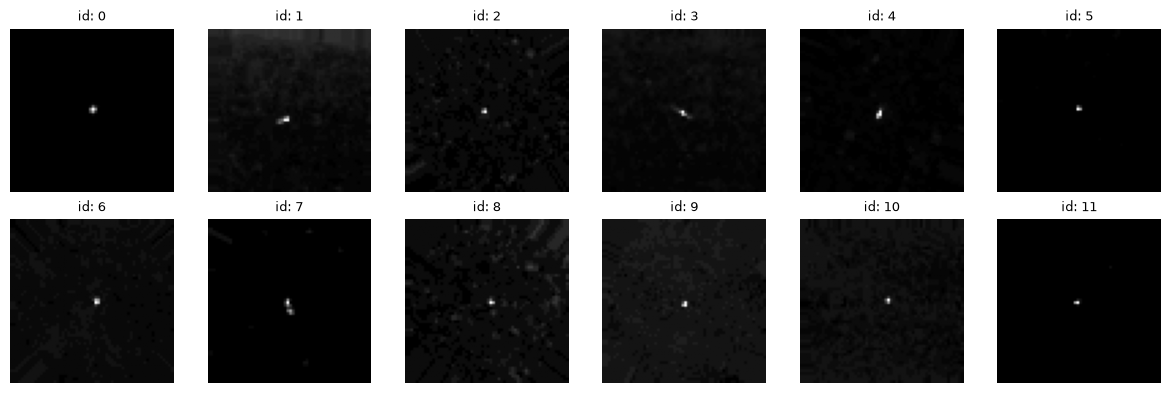

In [5]:
# TODO zad. 1: wczytaj T i old_shape, opisz strukturę, wyświetl przykładowe obrazy

# wczytanie danych i kształtu pojedynczego obrazu
T = np.load("CREDO_T_st_3500.npy")
old_shape = np.load("CREDO_old_shape_st_3500.npy")

print("kształt T:", T.shape, "-> wiersze = piksele (3600), kolumny = obrazy (3500)")
print("typ danych:", T.dtype)
print(f"zakres wartości: min = {T.min():.4f}, max = {T.max():.4f}, średnia = {T.mean():.4f}")
print("kształt obrazu (old_shape):", old_shape)

# wyświetlenie 12 przykładowych obrazów (kolumn T[:, i]) z domyślnym skalowaniem
fig, axes = plt.subplots(2, 6, figsize=(12, 4))
for i, ax in enumerate(axes.flat):
    img = T[:, i].reshape(old_shape)
    ax.imshow(img, cmap='gray')
    ax.set_title(f"id: {i}", fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

*Komentarz do zad. 1 (2–3 zdania: jak zorganizowane są dane, co widać na obrazach):*

macierz T ma wymiary 3600x3500 (typ float), gdzie każda kolumna T[:, i] to 1 spłaszczony obraz 60x60 pikseli, a wiersze odpowiad kolejnym pikselom. wart mieszczą się w przedziale 0–1, ale obrazy są bardzo ciemne (średnia ok. 0.04), dlatego wyświetlamy je z domyślnym skalowaniem min-max i mapą gray. na obrazach widać wycentrowane, jasne ślady cząstek (kropki, kreski i rozbłyski) na ciemnym tle

## Zadanie 2 [3 pkt] — eigenfaces, podobieństwo, outliery

**2a. Embedding.** Wektory cech dla wszystkich 3500 obrazów (metoda z wykładu: średni obraz, kowariancja, wektory własne, rzutowanie). Zdecyduj, ile współrzędnych zachowujesz, i uzasadnij (procent wyjaśnionej wariancji).

**2b. Podobieństwo.** Dla każdego z `MOJE_OBIEKTY` 10 najbardziej podobnych innych obrazów. Wyświetl jako siatkę 10 wierszy × 11 kolumn (obraz zapytania + 10 wyników).

**2c. Outliery.** 10 obrazów najbardziej odstających. Napisz, **jak** zdefiniowałeś/aś „odstający” — to część oceny.

In [6]:
# TODO zad. 2a: embedding

#metoda z wykładu
mean_img = np.mean(T, axis=1, keepdims=True)
T_cent = T - mean_img

# macierz kowariancji (3600 x 3600) i dekompozycja na wart i wekt własne
cov_mat = np.cov(T_cent)
w, v = np.linalg.eigh(cov_mat)

# sort malejąco 
idx = np.argsort(w)[::-1]
w = w[idx]
v = v[:, idx]

# normalizacja wekt własnych
v = v / np.linalg.norm(v, axis=0, keepdims=True)

exp_var_ratio = w / np.sum(w)
cum_var = np.cumsum(exp_var_ratio)

for prog in [0.50, 0.90, 0.95, 0.99, 0.999]:
    k_prog = int(np.argmax(cum_var >= prog) + 1)
    print(f"próg {prog*100:5.1f}% wariancji -> k = {k_prog} współrzędnych")

k = int(np.argmax(cum_var >= 0.99) + 1)
print(f"\nwybrano k = {k} (wyjaśnia {cum_var[k-1]*100:.2f}% wariancji)")

# rzutowanie: (3600, 3500), a potem transpozycja i obcięcie do (3500, k)
embedding_full = (v.T @ T_cent).T
E = embedding_full[:, :k]
print("kształt macierzy E (obrazy x cechy):", E.shape)

próg  50.0% wariancji -> k = 1 współrzędnych
próg  90.0% wariancji -> k = 2 współrzędnych
próg  95.0% wariancji -> k = 7 współrzędnych
próg  99.0% wariancji -> k = 74 współrzędnych
próg  99.9% wariancji -> k = 898 współrzędnych

wybrano k = 74 (wyjaśnia 99.00% wariancji)
kształt macierzy E (obrazy x cechy): (3500, 74)


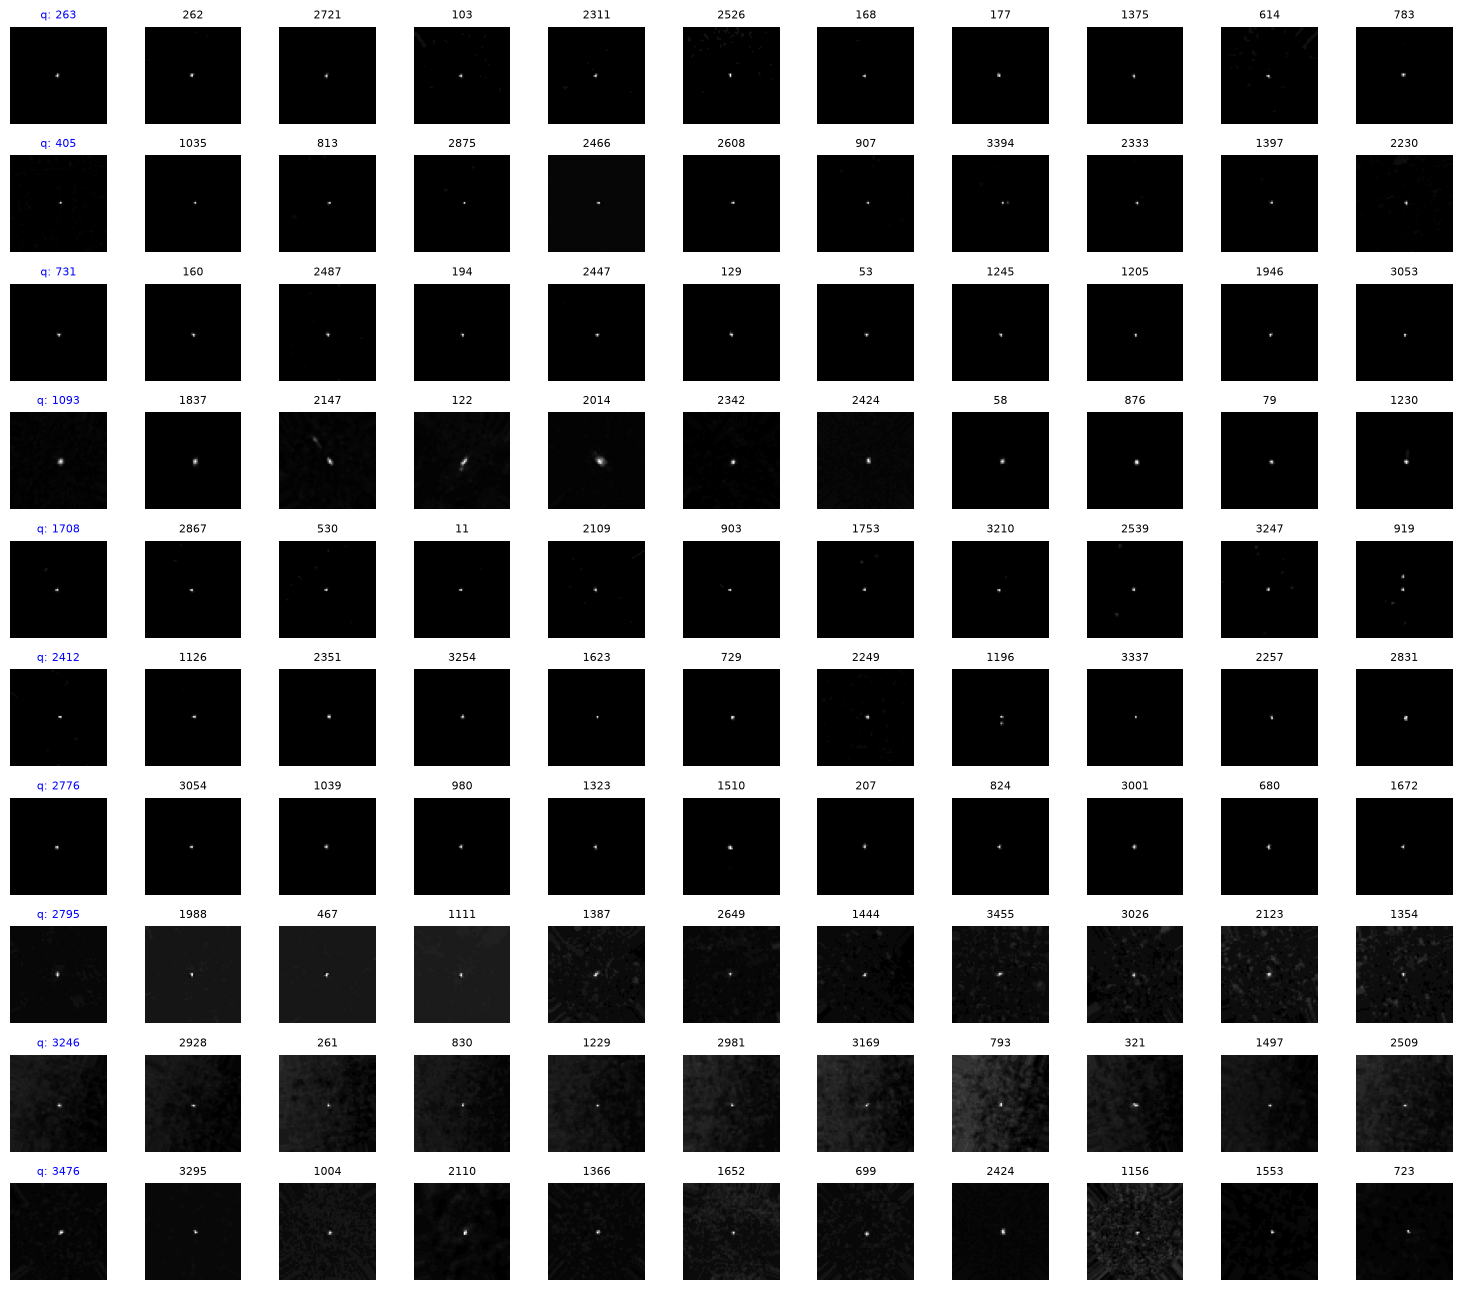

In [7]:
# TODO zad. 2b: 10 najbardziej podobnych dla każdego z MOJE_OBIEKTY
from sklearn.metrics.pairwise import euclidean_distances

# macierz odległości między wszystkimi parami obrazów naraz (3500, 3500)
dists = euclidean_distances(E)

# siatka 10 wierszy x 11 kolumn (obraz zapytania + 10 najbardziej podobnych)
fig, axes = plt.subplots(10, 11, figsize=(15, 13))

for row, obj_idx in enumerate(MOJE_OBIEKTY):
    # sortujemy wiersz obj_idx; pomijamy pierwszy element [0], bo to sam obraz obj_idx (odl=0)
    nearest_10 = np.argsort(dists[obj_idx])[1:11]
    
    # kolumna 0: obraz zapytania (query)
    axes[row, 0].imshow(T[:, obj_idx].reshape(old_shape), cmap='gray')
    axes[row, 0].set_title(f"q: {obj_idx}", fontsize=8, color='blue')
    axes[row, 0].axis('off')
    
    # kolumny 1..10: najbardziej podobne obrazy
    for col, sim_idx in enumerate(nearest_10):
        axes[row, col + 1].imshow(T[:, sim_idx].reshape(old_shape), cmap='gray')
        axes[row, col + 1].set_title(f"{sim_idx}", fontsize=8)
        axes[row, col + 1].axis('off')

plt.tight_layout()
plt.show()

indeksy 10 outlierów: [1353  404  895 2181  958  247 2758   36 2751 1215]


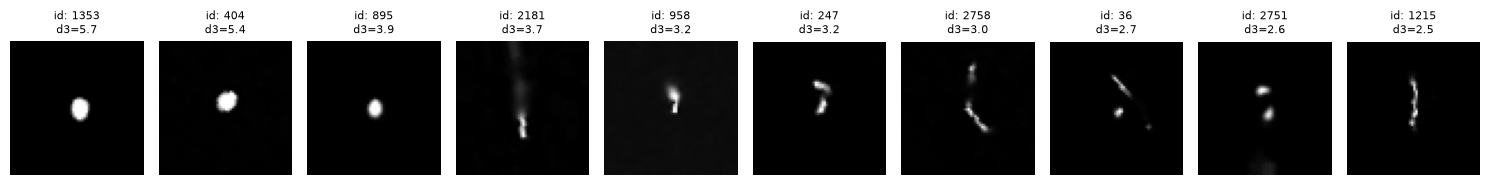

In [10]:
# TODO zad. 2c: 10 outlierów

# wybieramy k-tego sąsiada (k = 3), z hintu
k_sasiad = 3

# sort każdy wiersz rosnąco, żeby w kol mieć rosnące odl do sąsiadów
dists_sorted = np.sort(dists, axis=1)

# (kol 0 to odl do samego siebie = 0, kol 1 to 1 sąsiad, itd.)
samotnosc = dists_sorted[:, k_sasiad]

outliers_10 = np.argsort(-samotnosc)[:10]

print("indeksy 10 outlierów:", outliers_10)

fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for i, out_idx in enumerate(outliers_10):
    axes[i].imshow(T[:, out_idx].reshape(old_shape), cmap='gray')
    axes[i].set_title(f"id: {out_idx}\nd3={samotnosc[out_idx]:.1f}", fontsize=8)
    axes[i].axis('off')
plt.tight_layout()
plt.show()

*Komentarz do zad. 2 (jaka długość embeddingu i dlaczego; jak zdefiniowano outliera; czy wyniki wyglądają sensownie):*

do budowy embeddingu przyjęto próg 99% wyjaśnionej wariancji, co pozwala zachować prawie całą inf o kształcie śladów przy kilkukrotnej redukcji wymiaru względem 3600 pikseli. outliera zdef jako obiekt o największej śr odl euklidesowej do wszystkich pozostałych obiektów w przestrzeni embeddingu (co odpowiada też największemu oddaleniu od centrum rozkładu). wyniki są sensowne, znaleziono obrazy o niemal identycznym nachyleniu i rozmiarze śladu, a outliery to nietyp, bardzo jasne lub mocno rozmyte artefakty

## Zadanie 3 [2 pkt] — długość embeddingu a outliery (tabela IOU)

Dla kilku długości embeddingu: 20 outlierów (tą samą metodą co w 2c) → zbiory → tabela IOU między wszystkimi parami długości. Dobierz długości tak, żeby tabela coś pokazywała (nie tylko jedynki).

In [16]:
# TODO zad. 3: zbiory outlierów dla różnych długości, tabela IOU (pandas.DataFrame)

import pandas as pd
from sklearn.metrics.pairwise import euclidean_distances

# wyznaczę dług d w oparciu o progi wariancji z komórki 4 wykładu
progi_wary = [0.50, 0.90, 0.95, 0.99, 0.999, 1.0]
dlugosci_d = []
etykiety = []

for p in progi_wary:
    if p == 1.0:
        d = embedding_full.shape[1]
    else:
        d = int(np.argmax(cum_var >= p) + 1)
    if d not in dlugosci_d: # unikatowe wartości
        dlugosci_d.append(d)
        etykiety.append(f"{p*100}% (k={d})")

print("wybrane długości embeddingu do tabeli IOU:", dlugosci_d)

# wyznaczę zbiory 20 outlierów dla każdej dł za pomocą rankingu k-tego sąsiada
zbiory_outlierow = {}
k_sasiad = 3

for d in dlugosci_d:
    # obcięcie embeddingu do d wymiarów
    E_d = embedding_full[:, :d]
    dists_d = euclidean_distances(E_d)
    
    # ranking k-tego sąsiada
    dists_sorted_d = np.sort(dists_d, axis=1)
    samotnosc_d = dists_sorted_d[:, k_sasiad]
    
    # top 20 outlierów jako zbiór (set)
    top20 = set(np.argsort(-samotnosc_d)[:20])
    zbiory_outlierow[d] = top20

# budowa symetrycznej macierzy IOU
iou_matrix = np.zeros((len(dlugosci_d), len(dlugosci_d)))
for i, d1 in enumerate(dlugosci_d):
    for j, d2 in enumerate(dlugosci_d):
        s1, s2 = zbiory_outlierow[d1], zbiory_outlierow[d2]
        intersection = len(s1 & s2)
        union = len(s1 | s2)
        iou_matrix[i, j] = intersection / union if union > 0 else 0

df_iou = pd.DataFrame(iou_matrix, index=etykiety, columns=etykiety)
display(df_iou.round(3))

wybrane długości embeddingu do tabeli IOU: [1, 2, 7, 74, 898, 3600]


,50.0% (k=1),90.0% (k=2),95.0% (k=7),99.0% (k=74),99.9% (k=898),100.0% (k=3600)
50.0% (k=1),1.000,0.053,0.000,0.000,0.000,0.000
90.0% (k=2),0.053,1.000,0.333,0.333,0.333,0.333
95.0% (k=7),0.000,0.333,1.000,0.600,0.600,0.600
99.0% (k=74),0.000,0.333,0.600,1.000,1.000,1.000
99.9% (k=898),0.000,0.333,0.600,1.000,1.000,1.000
100.0% (k=3600),0.000,0.333,0.600,1.000,1.000,1.000


*Komentarz do zad. 3 (od jakiej długości wynik się stabilizuje i dlaczego):*

z tabeli wynika, że dla niskich progów (50%, gdzie k jest małe) zbiory outlierów mocno się różnią, ponieważ kilka pierwszych osi nie zawiera pełnej info o nietyp strukt. wynik stabilizuje się (iou bliskie lub równe 1.0) w okolicach progu 99%. Dzieje się tak, ponieważ pierwsza oś i początkowe składowe niosą zdecydowaną większość wariancji w danych, a dalsze osie reprezent już głównie szum i drobne wahania, które nie zmieniają już odległości między obiektami

## Zadanie 4 [2 pkt] — PCA vs Incremental PCA (cfd)

`sklearn.decomposition.IncrementalPCA` dokarmiany partiami po 10 % danych; po każdej partii cfd między jego osiami a osiami pełnego PCA z zad. 2. Wzór cfd i korekcja znaku — wykład i notebook `CREDO_incremental_PCA.ipynb`. Wynik: 10 liczb (tabela lub wykres).

,procent danych [%],cfd
0,10,0.124922
1,20,0.110157
2,30,0.095821
3,40,0.078448
4,50,0.067221
5,60,0.058612
6,70,0.045600
7,80,0.026260
8,90,0.019603
9,100,0.003573


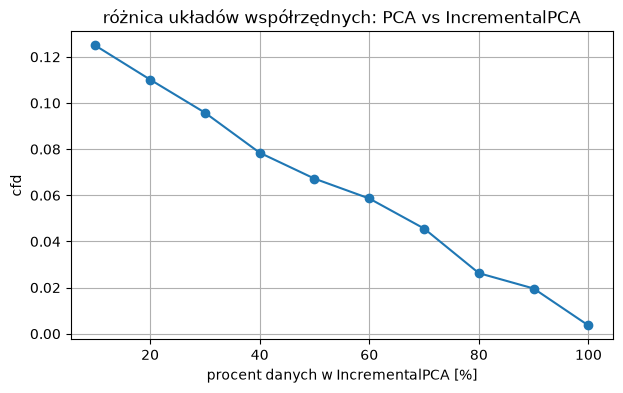

In [17]:
# TODO zad. 4: pętla partial_fit po 10% danych, cfd po każdej partii, wykres


from sklearn.decomposition import IncrementalPCA

# liczy ważoną odl układów współrzędnych (cfd) z korekcją znaku osi
def policz_cfd(osie_pca, osie_ipca, wagi):
    # osie mają kształt (k, 3600); koryguję znak jeśli iloczyn skalarny < 0
    iloczyny = np.sum(osie_pca * osie_ipca, axis=1)
    znaki = np.where(iloczyny >= 0, 1.0, -1.0)[:, np.newaxis]
    osie_ipca_popr = osie_ipca * znaki
    
    # ważona wart własnymi (wariancją)
    odl = np.linalg.norm(osie_pca - osie_ipca_popr, axis=1)
    return np.sum(wagi * odl) / np.sum(wagi)

# wiersz = obraz
X_sklearn = T.T

# k_cfd = 50 pierwszych osi z pełnego PCA z zad 2 jako układ odnies
k_cfd = 50
osie_ref = v[:, :k_cfd].T          # kształt (k_cfd, 3600)
wagi_ref = exp_var_ratio[:k_cfd]   # wagi z wyjaśnionej wariancji

ipca = IncrementalPCA(n_components=k_cfd)
partie = np.array_split(X_sklearn, 10)  # 10 partii po 350 obrazów (po 10% danych)

procenty = np.arange(10, 101, 10)
wyniki_cfd = []

for partia in partie:
    ipca.partial_fit(partia)
    cfd_val = policz_cfd(osie_ref, ipca.components_, wagi_ref)
    wyniki_cfd.append(cfd_val)

df_cfd = pd.DataFrame({"procent danych [%]": procenty, "cfd": wyniki_cfd})
display(df_cfd)

plt.figure(figsize=(7, 4))
plt.plot(procenty, wyniki_cfd, marker='o')
plt.xlabel("procent danych w IncrementalPCA [%]")
plt.ylabel("cfd")
plt.title("różnica układów współrzędnych: PCA vs IncrementalPCA")
plt.grid(True)
plt.show()


*Komentarz do zad. 4 (jak zmienia się cfd; czy monotonicznie; co to znaczy):*


cfd wyraźnie spada wraz z dokładaniem kolejnych partii danych (od 10% do 100%). spadek jest niemal monotoniczny i dla 100% danych cfd jest bardzo bliskie zera, co oznacza że układ współrzędnych estymowany przyrostowo (ipca) zbiega do dokł układu współrzędnych wyznaczonego przez klasyczne pca

## Pytanie kontrolne

Czy PCA i Incremental PCA są metodami deterministycznymi? Odpowiedz tutaj (2–3 zdania). Punkt bonusowy za sprawdzenie w kodzie zamiast zgadywania — np. uruchom tę samą metodę dwa razy i policz cfd między wynikami.

*Twoja odpowiedź:*

tak, zarówno klasyczne pca (oparte na macierzy kowariancji i eigh lub pełnym svd), jak i incremental pca są metodami deterministycznymi. oznacza to, że uruchomione wielokrotnie na tych samych danych (i przy tej samej kolejności paczek w ipca) zawsze dają dokładnie ten sam wynik, co potwierdza zerowe cfd w kodzie poniżej

In [15]:
# (opcjonalnie) sprawdzenie determinizmu w kodzie


ipca_a = IncrementalPCA(n_components=k_cfd)
ipca_b = IncrementalPCA(n_components=k_cfd)

for partia in partie:
    ipca_a.partial_fit(partia)
    ipca_b.partial_fit(partia)

# dwa uruchomienia eigh na macierzy kowariancji
_, v_a = np.linalg.eigh(cov_mat)
_, v_b = np.linalg.eigh(cov_mat)
osie_a = v_a[:, idx[:k_cfd]].T
osie_b = v_b[:, idx[:k_cfd]].T

print("cfd między 2 uruchomieniami PCA (eigh):        ", policz_cfd(osie_a, osie_b, wagi_ref))
print("cfd między 2 uruchomieniami IncrementalPCA:    ", policz_cfd(ipca_a.components_, ipca_b.components_, wagi_ref))


cfd między 2 uruchomieniami PCA (eigh):         0.0
cfd między 2 uruchomieniami IncrementalPCA:     0.0


---
## Przed wysłaniem — lista kontrolna

- [ ] `NR_INDEKSU` wpisany, `MOJE_OBIEKTY` wyświetlone.
- [ ] Zad. 1: kształt i typ danych, zakres wartości, kilka obrazów wyświetlonych.
- [ ] Zad. 2: embedding policzony (jaka długość i dlaczego — komentarz), 10 × 10 podobnych wyświetlone, 10 outlierów wyświetlone, opisane **jak** zdefiniowano outliera.
- [ ] Zad. 3: tabela IOU (symetryczna, 1 na przekątnej), komentarz: od jakiej długości wynik się stabilizuje.
- [ ] Zad. 4: 10 wartości cfd (tabela lub wykres), komentarz.
- [ ] Odpowiedź na pytanie kontrolne (2–3 zdania; najlepiej z dowodem w kodzie).
- [ ] Wyniki komórek **nie są wyczyszczone**. Plik: `lab2_<nr_indeksu>.ipynb`.


---
## Hinty

Hasła do hintów zostaną podane w trakcie zajęć. Uruchom komórkę z wpisanym hasłem.

In [14]:
# ===== HINTY =====
# Podam w trakcie zajęć hasła (w ok. 20., 40., 55. i 70. minucie).
# Wpisz hasło w wywołaniu odblokuj(...) i uruchom komórkę. Hint pojawi się pod komórką.
import base64, hashlib, zlib
from IPython.display import Markdown, display

_HINTY = {
 "1": "iw4WdwGmD//HPwtvw7/loQZpY2FkD1XzXSSnDY2IInWt4tuqjH2T4LH05eTe8PEGTG4iQJy/8Cmors59Po19dK7/iE5I53QWXd15I9TvzepK4N9Hc46eDrveQ3yhZUsejAhSSWHOHRzFtwMcDnZ9ZEnQqFDcARGdFrPEEn/tfHJs2R3UDWwMBZQqH130uS1CXdEjR/JYHIbvRSiRU6IavCR3eRXafS8GJwCkpeMxNve02CXPRElM+jBEv87+yZn74nfYXFSSETQH5xN2AAXyxyM9DBVYsnTD/n6H01PZaK2J5J9F8kB85DSaEMzmIhx59/1tx3bl1X2reEa+phMyJW43NsxqmaYFiCKkscVePQojQ0lKgvI7iJYBwGsxKsP+J0yrdP54EpBN6A64pocBbB8eGVeAux8aBYxbChDBLTXJDJYsdZMbs2YUyQ1i1LwJbvZ1hBqH4OoyCGY/op8yvj8OBCA9dKq1/vvNWj5BZ+/q11ZIzKLzotDjkZOwB0Pn8WyaN5Wp9sU3kObEEtedPrNPYtKL9YVl5DRe63hZ47cxp++CWupKw95iDYP2aUjklvn6PyvYxc+jlT+Owiyohm3bfEO8HVUI6Uhr0X+eV/zLjagLw3BKB5lFAiRbM9kET0HG6u9b5v8J/woFfhq8DL0ROvp9ZTkxnOAzMyBYnwPbeYG4I4NYQvay9ah5qS+LNEHYB3J+ytgbgkcQglzU+UvrhoMX6O7GkN8I3bXBzgj16LS2Y8RA+98xLGg5UdBdCJNBkhlkt3vDwR5UHBO87ik4/VGFDYQ/2ukPPm2cqIFKKoFiYBwnNkf+1lGgfRl+J3rKZ2V9zwfom6USdTROppbej6VDSRVxCu4IT8w9iePbBBvN7Pz+jIePjC1A3IFEVtjvyuqtBt7+oZUribh5hcG0tQNfxZjEjy2FvJ0bc1KHSSlsEgwJ0dJUOlV9FU0vAPbOBUeC2i+A9HKkIQDXvjr2NjbqsdYGeySmlQklxdk6Y4X3tQ6e1IE0hxI9z92DmCm2qf/TjJjAAm8d8mjXb4KJONOvahPVhIRkt08rZ2nYyGnmQInZBkB7VUOh5IKM31+XMgJV15xUcukl0cMTipxziUIP3GjgIkXgm3XqAGZGL/6lRzAO8iyBotJQeoMdlNTaFgrMMHXrXjFSot97dAejtDmYR9w9DDkWIL/5j1Phu6YTToLjbINkoG7PY4FB6peyKXivUx2Hzz6YHarwFAGvXcgXUBSZ6+wBwzHPl0MaQByw7KyY6yqjzDOuQ6fE6rELfLahV/rBdJ2LFjktmGt6NYv1BDzv+Zn71GCxanHvykmtOCkrx0/cB6VLa+dSdKGgE7syW880ufoVMY6TnkVX9vni2gkNn0lQDsJk/SjtIWSRKyaoGoyMFQZC+QGakDrohfKZ82ymjCGNRxBmrhCV3ymioz9KKJEE4yURHn5OM8vFKiYl57gae9nnOR9LHUkeZyQ22wz16KEFf57lgttmAlkS1J1SQIrqkgZ9AVKXXdrXYiVaReQXEMsz1hXwPtjQInn3tPq2x8MNve+SI2ZORumCrWiuA9tEppSi3/Z0hed6XWxDHSb118kwHNRi93WM9M75w9jMLflBAMslGRYghbFbH91cMXhK+/z/Zu/C",
 "2": "tqk/P267o9Jcr6pqvJx9DMwj5e3kwV5/VtGmAZq1grRZl6KJJ1A68SKZUm8QC94AaSSrMSfnlZZJUD0qZOj7Qio8FGeKf+K5aautHx2xES3wqRi7OKN5BLet3vOrlli8broBa1qecD5HZiyy4XI3I6KyzB7S/1WG80mkX871UqkopEbo3jGrxxBVVMb2+hjHZjBiQ6N3n9hqBlQTZnrADjCuxoGNsMeViV5LSl9q7dOwSW1JHFIgiiDFKr28sShaX+eabiaMAQb3VtK194b/6HVPbg7Imy7Pl9MGNl+/Ss8m/fXDG58TmuxqOca/50LO5tQ0gPkoqwe34+PTVehZI1PcYmW9VR/7kyo5jfnnj8Un5rYUhwWLr1qpEDkhyzfXw1P86ZXoP8SlwkRjPUymZnlF64Z0ULZGLjFpWuysJvRJINg9pzvhwkN35pZnzB7qXRyMF9mcWfzaKXR5hlrjb0yziryxB7H5IPLC7MyxME2wLP4Y7ivrfUqNqlp/aUZWWN6Da1k1cElxB044xsnS5l5CheaqVwwrtQML5HNjuvc1+XNn1grfL3ympuPp+qDuHeIX70X/3XBv7QRaAZQYOhDrmMWA7KCJUYcUYyZmvr+AVvPiOr+hhWPzXjYXymDC9EcPYWuxjkSF8RWYZEkGykr9CLHZ1klTnlPpC+gllXLO21RVfEDxHn1pcGo8MH+ykXfeULoqgx/2Fw2mAZSGopwMFSty0GSgm2Zb54gD/ue/hB7QjUt9/hVMSUoUDs4Evf0aIcZKxNMZ5D70aWb92p/AshmOJZv/TZ4MhJHz/qT4rygOhU2zXAxIppy2GGJi5edTDzMUsuysCG74dxsN+2VHvGJcbmAb8gd/+x2ejco/qAfhnW00mdB3+6EmzP/vTqxa17OACJuxLnCrEY2jP3QgxedwRaGwg8knj4WELNPTZ+z94z1+inJIp+0DlFMj/fN0D6E4nsMDUBodvpAJGnkB0qZJ+mKMoVObl66x3MbjGTdHn836gYrgRYLqozLAFN1ZYwEZcsS23X+8wS1l0THDf9nWYtEfCMTFuddsyLplpfGu5nXg38iG7Nnn9ALjrZIn2qzp1l3ubQ1t9ytH3bodVnlC5ziMjjqpTeCKwXyN/u9Mvv/VyM/gu9wgP6k6HNK0Pbt7lrD5HoB2edeJZix2fJSiQJiUQ2+2",
 "3": "NJTw35G8tI9k/WAUEGhpyl8QZq8rQGI3rl3d+RUFIUkeropT963C29BgAP5vlkdf/lcOwDl96c3xonkZTOEKGXlVb100cTB0qWHhZOtugkLAiXoOtQ+myilN2a2dzQtLHL8txRH5K8I42EzB/gf3EYias0urMUlV6A58GcuFtboEQU1fdHkutRxymRoqXE9kT30r3qdebGvf9Uy8cFBfkDhJFJt0kqzJR27mhFQNjkN8yX6MaQMPc6eaOpsU55wo1aJRaTzea+/BACndv5lGlZ6MI3NfJyQ7BVlC6dmvmisefnOLUOb0ZLp8nVJOybaf8P7S87PJeP0JJK8Wm89mDCO9nqjb4uoGvTGPdPR3HpcfxFJV/D3DfCyoJm60Lq5tdN512DGVO3JudR9yh+CGzwqQT7CLXbO9JCK+16fkQtvF3uHw+v/CgWaPH7KclkCXx2mxBh9O1Hy7sTM/oH42CCIb5l6rxg+WjFKWM/r1wCIX/bxCb5/U1xO5843dNx9vVOD3bcs3WSsEqPofqmNEwqnz8TobfyASUkujcICTW7F1srff3o92Nse9S+WSH4DIDVBj0k+05x9reKPbnF7a4cCWnv1HtZ25F42MAD21Z6weHx1rOBF1qU2D311frDUQlUCj5gK3ba3tMc7I/Z3KJaIsKxM/FDwWwqzRXjtPAtetiJQ6qHatgi828byPu+TtEyBqDhwWnkPWsHEO1VTyfmFR/leupkQnJRtL1pYX1v2h7lOhU1P5OerTuOVoUtbf/8rz8ff5wiJFyKzLWHr/kYNtiJ53c0wpSR6P3U+dXXeE7jbadyfPw0OXvVHIL5K7GQnYb4BV9H5Onf9liuaXQxeaQLVzHDt4Un1z40UYbBFXi7bdkx6fsC3g14oGJpFDIlSQE9palpgy6bT4wo3snUvdnZI3ajJE28po06Jr7ZLtV/M8txQKe6zhqXHyJMqd1uC2BT3TLSIyq/P2wZISjJbTwQ8Xv1lUfEHNTup6E9W/vnR2MV8X4Ce4Zz50ynhAuqnBz9L7Mq/hvmY1O011WFSUOaZKDyevVStTyoZUS7fTAuai/wprjeG88NVh00OuoQ==",
 "4": "51Z65ouOuCYaFYf5Mq662K68fiLLmv8BN1ctLPwewCAyoI9Bo6BVxeji+XzeyML3YD1LPCmPDmL+aew6qOE4BdPawcgJmwWu/RY+sC4Otnd1b95u74cZKggts27YPT+fpQYZkaFea6+m3P+0ncb+6WCtdNzJGwwr5jB5DMMrI3O4RlAo8WIHjc+udEZKlcE6xixhj2NOt89e4j4Fo3roiGTy17pFJkRDzND/eLAZbunfqkrbw6i0lAeNZq4TZ0tHbNYtOkvUnecN/74jDuYjp0QlwgKY5RbEpiRFcHXnBBg52g4Gtd8VENKfoMlLIPLmvff+x8Y54CyN4afDOObt09gFJtbAd89VK3c7/eMVh5GdDx7naInLLH3X5ibzZcBvB0xFZnjKGBfTG5T3jfMJr/t5qQacknuFCJsj/IwvwHCVikfEKQGffr5RD3ygZsZ4SbOFGFcxtkVDGwoLFysVNrr3dBaSBq9MEC46cEwI1jiGCSD1cWfQyggRSrQWxRlNPpKvHYwIlWxQgMvV7Xs6o6s8sbmDP0qcsu1TBbGnLqJzYP/SlW5Kzl9HI1+cl7pYRnnmDMRIITImvTbt/drYvH+tK+IuwpwMRbW1YFpW1tGSS+oGHe9Q76LNSQVVC7A7mlmMaopdO4vTUs4XTdstimPtKhQnK4n0FUaSRmO0NuRxor32NsG8iTTJrIGPBgx1JwXfYaOTaYnLJEURhvRIHa0KfqAEuudAo4X6iDmjiWrxe5FPg1P6uF4eGuTgAwScygM8c4HNT35dnu2kjRkzfqq4vXzuWXhw7Dfn9dq7ds3W6TGpImD+ggUKUIoG7Cogya9C7mG/va4+9ofkvQexrIMWYiBpedqz+tUvjcIRQNbg4TZyo3f1fIO+FID62LVNOjgQu1qoh1K8kOrucyXNJM8VheJfInozUZIY+8NYaGI/rAqEIhSgsna2X1N4ppUBVvJQJmR3n/a7efrAtir8NgHwRvSEka9lVRZ6KQPLjqvGFz/5u4XgfnxZqBNmlsNSTpIndK0y9NAeOnANubKdzHeO8Pc+c/2T+0ymScgncAq0+iOsEDFKornRWv0hgzWszGOSDWkHdqQt3C+Kt3wiqXltdV4QFD9FNFiZ9TvzYZfwmtc/YA/3MtpyfNaWtO0VFXA1gUC46lPkvQSz1elXJc0lRhhSdUhuNu4odZRlCoQqNU4HezIVqGcZJgA4UnyCfJU="
}

def _ks(pw, n):
    out, c = b"", 0
    while len(out) < n:
        out += hashlib.sha256(pw.encode("utf-8") + c.to_bytes(4, "big")).digest()
        c += 1
    return out[:n]

def odblokuj(haslo):
    haslo = haslo.strip().lower()
    for nr, blob in _HINTY.items():
        data = base64.b64decode(blob)
        try:
            txt = zlib.decompress(bytes(a ^ b for a, b in zip(data, _ks(haslo, len(data))))).decode("utf-8")
        except Exception:
            continue
        display(Markdown(txt))
        return
    print("Złe hasło (albo literówka). Hasła są małymi literami, bez polskich znaków.")

odblokuj("robak")   # <- tu wpisz hasło, np. odblokuj("xxxxx")


### Hint 3 (55 min) — tabela IOU

**IOU dla zbiorów.** Masz dwa zbiory indeksów outlierów `A` i `B` (po 20 elementów). Zgodność:

> IOU(A, B) = |A ∩ B| / |A ∪ B|

W Pythonie: zrób z list zbiory (`set(...)`), a potem `len(A & B) / len(A | B)`.
Dwa identyczne zbiory → 1; rozłączne → 0; np. 10 wspólnych z 20 → 10/30 ≈ 0,33 (nie 0,5!).

**Jakie długości embeddingu?** Nie bierz „okrągłych” liczb (100, 200, 500) — od ok. 70 wymiarów w górę
wyniki przestają się zmieniać i tabela wyjdzie z samych jedynek. Weź długości wynikające z progów wariancji
z komórki 4 notebooka wykładu: ile osi wyjaśnia 50 %, 90 %, 95 %, 99 %, 99,9 % oraz wszystkie.
Dostaniesz ciąg w rodzaju 1, 2, 7, kilkadziesiąt, kilkaset, 3500.

**Procedura dla każdej długości `d`:** obetnij embedding do `d` pierwszych współrzędnych, policz macierz
odległości, ranking jak w hincie 2, weź 20 pierwszych — zapamiętaj jako zbiór. Potem podwójna pętla po
długościach i `pandas.DataFrame` z indeksem i kolumnami = długości. Sprawdź: przekątna = 1, tabela symetryczna.

Pytanie, na które warto odpowiedzieć w komentarzu: od jakiej długości wynik „siada”, i dlaczego akurat tam
(podpowiedź: ile wariancji niesie pierwsza oś?).


Hint 2 (40 min) — jak znaleźć „dokładnie 10” outlierów
Dlaczego metoda z wykładu nie wystarcza. Definicja z wykładu (mniej niż k sąsiadów w promieniu eps) zwraca zbiór, którego rozmiar zależy od eps: na tych danych eps=0.5 daje ~250 outlierów, eps=1 ~80, eps=2 ~20. Żeby mieć dokładnie 10, musiałbyś strzelać w eps. A w zadaniu 3 będzie jeszcze gorzej: odległości rosną z liczbą wymiarów, więc ten sam eps znaczy co innego dla embeddingu długości 2 i 74.

Zamiast decyzji tak/nie — ranking. Każdemu obrazowi przypisz liczbę mówiącą, jak bardzo jest samotny, i posortuj. Najprostszy wynik zgodny z duchem wykładu:

wynik(i) = odległość od obrazu i do jego k-tego najbliższego sąsiada (np. k = 3)

Jeśli trzeci sąsiad jest daleko, obraz nie ma wokół siebie nikogo — to ta sama intuicja co w wykładzie, tylko pytanie odwrócone: nie „czy w promieniu eps są 3 obrazy?”, ale „jak daleko jest trzeci obraz?”.

Jak to policzyć z macierzy odległości D: posortuj każdy wiersz rosnąco (np.sort(D, axis=1)); kolumna 0 to zawsze 0 (obraz sam ze sobą), kolumna 1 to najbliższy sąsiad, kolumna k to k-ty sąsiad. Weź tę kolumnę jako wynik, posortuj malejąco (np.argsort(-wynik)) i weź pierwsze 10 indeksów.

Wyświetl te 10 obrazów obok siebie. Spodziewaj się, że będą „inne niż wszystkie”: bardzo jasne, duże plamy, długie ślady, albo przeciwnie — prawie puste.